# 02 — Partición y modelos base

**Objetivo del proyecto:** comparar modelos de regresión para predecir los años que una persona tarda en pagar
su crédito de ICETEX. **Los años son simulados** (ver cuaderno 01), así que las conclusiones aplican al simulador.

## El pipeline de ML

1. **Datos:** base limpia + variable objetivo simulada.
2. **Partición:** 80 % desarrollo y 20 % prueba. La prueba no se toca hasta el cuaderno 05.
3. **Preprocesamiento:** estandarizar variables numéricas y codificar las categóricas (one-hot).
4. **Modelo:** línea base, regresión lineal, árbol, Random Forest y kNN.
5. **Evaluación:** validación cruzada de 5 particiones sobre el conjunto de desarrollo.
6. **Selección de hiperparámetros** (cuadernos 03 y 04) y **comparación final en prueba** (cuaderno 05).

In [1]:
import sys
sys.path.append("../src")  # por si el paquete no está instalado con pip install -e .

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from proyecto_ml.data import SEMILLA, cargar_dataset, particionar
from proyecto_ml.metrics import resumen, rmse
from proyecto_ml.models import ARBOL, BOSQUE, KNN, LINEA_BASE, LINEAL, NOMBRES, construir_modelo

RESULTADOS = Path("..") / "resultados"
RESULTADOS.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_colwidth", 80)

from sklearn.model_selection import KFold, cross_validate

## Datos y partición

In [2]:
datos = cargar_dataset()
X_dev, X_test, y_dev, y_test = particionar(datos)   # 80 % desarrollo, 20 % prueba (reservada)
print("desarrollo:", X_dev.shape, "| prueba:", X_test.shape)
datos[['anios_pago']].describe().T

desarrollo: (6972, 7) | prueba: (1744, 7)


,count,mean,std,min,25%,50%,75%,max
anios_pago,"8,716.000",5.800,3.062,0.698,3.433,5.341,7.654,23.264


## Línea base y modelos con hiperparámetros por defecto

Se compara cada modelo con **validación cruzada de 5 particiones** sobre el conjunto de desarrollo. La **línea base**
predice siempre el promedio de los años: es el piso contra el cual cualquier modelo debe ganar.

In [3]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

filas = []
for nombre in NOMBRES:
    r = cross_validate(construir_modelo(nombre), X_dev, y_dev, cv=cv,
                       scoring="neg_root_mean_squared_error", return_train_score=True)
    filas.append({
        "modelo": nombre,
        "RMSE entrenamiento": -r["train_score"].mean(),
        "RMSE validación cruzada": -r["test_score"].mean(),
        "desv. entre particiones": r["test_score"].std(),
    })
tabla_base = pd.DataFrame(filas)
tabla_base

,modelo,RMSE entrenamiento,RMSE validación cruzada,desv. entre particiones
0,Línea base (media),3.053,3.052,0.088
1,Regresión lineal,1.432,1.440,0.036
2,Árbol de decisión,0.963,1.444,0.026
3,Random Forest,0.999,1.337,0.015
4,kNN,1.251,1.425,0.017


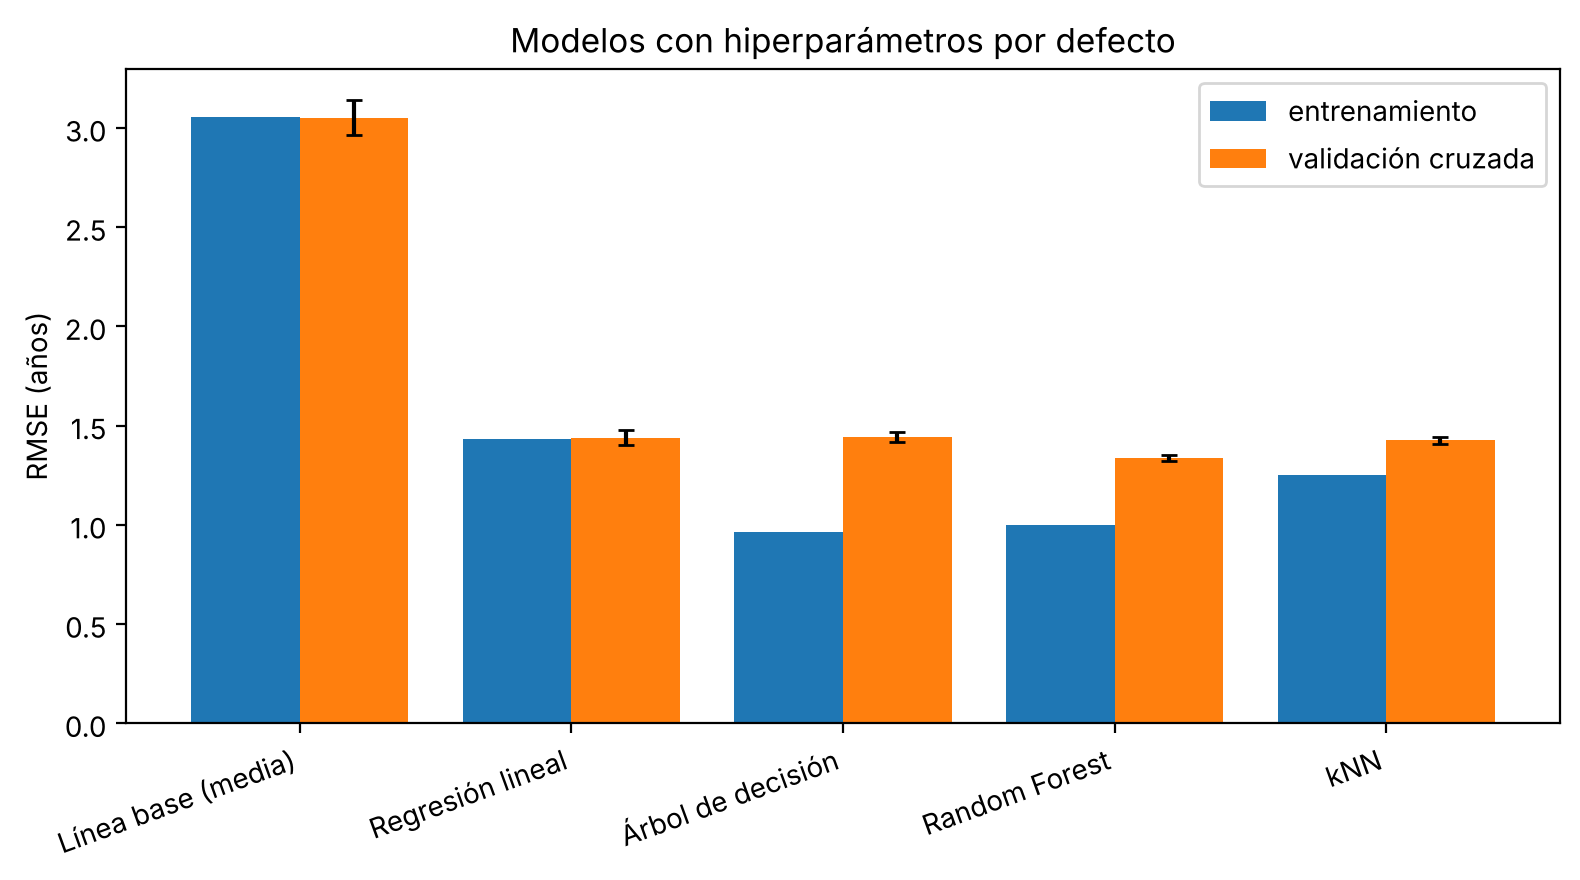

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(tabla_base))
ax.bar(x - 0.2, tabla_base["RMSE entrenamiento"], width=0.4, label="entrenamiento")
ax.bar(x + 0.2, tabla_base["RMSE validación cruzada"], width=0.4, label="validación cruzada",
       yerr=tabla_base["desv. entre particiones"], capsize=3)
ax.set_xticks(x)
ax.set_xticklabels(tabla_base["modelo"], rotation=20, ha="right")
ax.set_ylabel("RMSE (años)")
ax.set_title("Modelos con hiperparámetros por defecto")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTADOS / "02_modelos_base.png", dpi=150)
plt.show()

### Lectura de resultados
- La **línea base** (predecir siempre el promedio) tiene RMSE ≈ 3,05 años. Todos los modelos la superan por mucho; la regresión lineal ya baja a 1,44.
- El **árbol sin restricción** tiene RMSE de entrenamiento 0,96 y de validación cruzada 1,44: memoriza la muestra (sobreajuste). Su error de entrenamiento no llega a 0 porque hay personas con exactamente las mismas variables y resultados distintos, por el azar del simulador.
- El **Random Forest** ya es el mejor sin ajustar (1,34). Regresión lineal, árbol y kNN quedan entre 1,42 y 1,44.

### Mi análisis
*(Escríbelo con tus palabras. Preguntas para guiarte: ¿cuánto mejora cada modelo a la línea base? ¿Qué modelos tienen un RMSE de entrenamiento mucho menor que el de validación, y qué significa eso? ¿Qué ventaja o desventaja tiene cada modelo antes de ajustar hiperparámetros?)*